In [ ]:
import spacy

nlp = spacy.load("en_core_web_sm")

In [24]:
def chunk_abstract(
    text,
    window_size=8,
    overlap=2
):

    doc = nlp(text)

    sentences = [
        sent.text.strip()
        for sent in doc.sents
    ]

    chunks = []

    step = window_size - overlap

    for i in range(
        0,
        len(sentences),
        step
    ):

        chunk = sentences[
            i : i + window_size
        ]

        if chunk:

            chunks.append(
                " ".join(chunk)
            )

    return chunks

In [25]:
import pandas as pd

df = pd.read_json("/home/razor/Documents/alzheimers-rag/data/corpus/alzheimers_cleaned.jsonl", lines=True)

In [26]:
df.head()

,pmid,title,abstract,journal,year,text,abstract_length
0,42088846,Criterion and convergent validity of plasma bi...,<b>INTRODUCTION</b>: Despite expanding use of ...,"Alzheimer's & dementia (Amsterdam, Netherlands)",2026,Criterion and convergent validity of plasma bi...,1236
1,42088648,Insulin Resistance Across Cerebrovascular and ...,Insulin resistance (IR) Insulin resistance (IR...,Neuropsychiatric disease and treatment,2026,Insulin Resistance Across Cerebrovascular and ...,1846
2,42088524,Body weight and waist circumference are differ...,Thyroid hormones (TH) and neurotransmitter ore...,Journal of clinical & translational endocrinology,2026,Body weight and waist circumference are differ...,1707
3,42088504,Angiotensin-converting enzyme overexpression i...,"Angiotensin-converting enzyme (ACE), a dipepti...",Frontiers in immunology,2026,Angiotensin-converting enzyme overexpression i...,1168
4,42088298,Mindfulness-based stress reduction combined wi...,Non-pharmacological approaches are preferable ...,Frontiers in aging neuroscience,2026,Mindfulness-based stress reduction combined wi...,1743


In [27]:
chunked_records = []

for _, row in df.iterrows():

    chunks = chunk_abstract(
        row["abstract"]
    )

    for i, chunk in enumerate(chunks):

        chunk_record = {

            "chunk_id":
                f"{row['pmid']}_{i}",

            "pmid":
                row["pmid"],

            "title":
                row["title"],

            "text":
                chunk,

            "year":
                row["year"],

            "journal":
                row["journal"]
        }

        chunked_records.append(
            chunk_record
        )

In [28]:
print(
    "Total chunks:",
    len(chunked_records)
)

Total chunks: 2046


In [29]:
chunk_lengths = [
    len(c["text"])
    for c in chunked_records
]

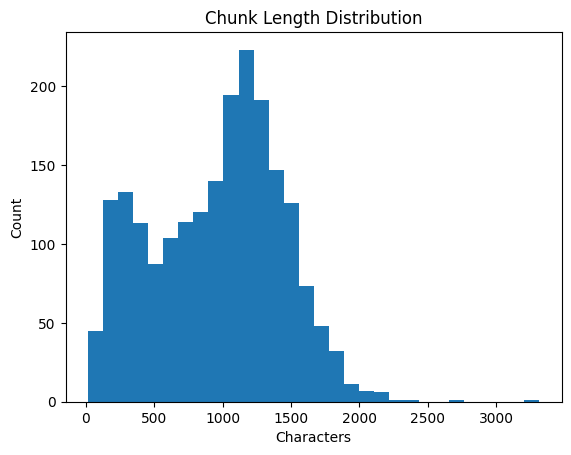

In [30]:
import matplotlib.pyplot as plt

plt.hist(chunk_lengths, bins=30)

plt.title("Chunk Length Distribution")

plt.xlabel("Characters")

plt.ylabel("Count")

plt.show()

In [32]:
import json

with open(
    "/home/razor/Documents/alzheimers-rag/data/processed/alzheimers_chunks.jsonl",
    "w",
    encoding="utf-8"
) as f:

    for chunk in chunked_records:

        f.write(
            json.dumps(chunk) + "\n"
        )